# Rapid Flood Extent Mapping from Sentinel-1 SAR Imagery using Multi-Temporal Attention U-Net

In [1]:

# ------------------------------------------------
# 1. IMPORT LIBRARIES
# ------------------------------------------------

import os
import sys
import json
import random
import platform
import shutil
import gc
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

# ------------------------------------------------
# 2. PROJECT CONFIGURATION
# ------------------------------------------------

PROJECT_NAME = (
    "Rapid Flood Extent Mapping from Sentinel-1 SAR "
    "using Multi-Temporal Attention U-Net"
)

DATASET_NAME = "Kuro Siwo"
REPOSITORY = "orion-ai-lab/Kuro-Siwo-Webdataset"

SEED = 42

# Kaggle working directory
PROJECT_DIR = Path("/kaggle/working/flood_mapping_project")

# ------------------------------------------------
# 3. CREATE PROJECT DIRECTORIES
# ------------------------------------------------

DIRECTORIES = {
    "data": PROJECT_DIR / "data",
    "checkpoints": PROJECT_DIR / "checkpoints",
    "logs": PROJECT_DIR / "logs",
    "results": PROJECT_DIR / "results",
    "configs": PROJECT_DIR / "configs",
    "figures": PROJECT_DIR / "figures"
}

for directory in DIRECTORIES.values():
    directory.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------
# 4. SET RANDOM SEEDS
# ------------------------------------------------

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Deterministic behaviour where supported
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# ------------------------------------------------
# 5. SELECT COMPUTING DEVICE
# ------------------------------------------------

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# ------------------------------------------------
# 6. ENVIRONMENT INFORMATION
# ------------------------------------------------

print("=" * 70)
print("PROJECT INITIALIZATION")
print("=" * 70)

print(f"Project          : {PROJECT_NAME}")
print(f"Dataset          : {DATASET_NAME}")
print(f"Repository       : {REPOSITORY}")
print(f"Python           : {platform.python_version()}")
print(f"Operating System : {platform.platform()}")
print(f"PyTorch          : {torch.__version__}")
print(f"NumPy            : {np.__version__}")
print(f"Pandas           : {pd.__version__}")

# ------------------------------------------------
# 7. HARDWARE INFORMATION
# ------------------------------------------------

print("\n" + "=" * 70)
print("HARDWARE INFORMATION")
print("=" * 70)

print(f"CPU cores        : {os.cpu_count()}")
print(f"Compute device   : {DEVICE}")

if torch.cuda.is_available():

    gpu = torch.cuda.get_device_properties(0)

    print(f"GPU              : {gpu.name}")
    print(f"GPU memory       : {gpu.total_memory / 1e9:.2f} GB")
    print(f"CUDA version     : {torch.version.cuda}")

else:
    print("GPU              : Not available")

# ------------------------------------------------
# 8. RAM INFORMATION
# ------------------------------------------------

try:
    import psutil

    memory = psutil.virtual_memory()

    print(f"Total RAM        : {memory.total / 1e9:.2f} GB")
    print(f"Available RAM    : {memory.available / 1e9:.2f} GB")

except ImportError:
    print("RAM information  : psutil not installed")

# ------------------------------------------------
# 9. STORAGE INFORMATION
# ------------------------------------------------

disk = shutil.disk_usage("/kaggle/working")

print(f"Total disk       : {disk.total / 1e9:.2f} GB")
print(f"Free disk        : {disk.free / 1e9:.2f} GB")

# ------------------------------------------------
# 10. SAVE PROJECT CONFIGURATION
# ------------------------------------------------

CONFIG = {
    "project_name": PROJECT_NAME,
    "dataset": DATASET_NAME,
    "repository": REPOSITORY,
    "random_seed": SEED,
    "device": str(DEVICE),
    "python_version": platform.python_version(),
    "pytorch_version": torch.__version__,
    "environment": "Kaggle"
}

config_path = DIRECTORIES["configs"] / "project_config.json"

with open(config_path, "w") as file:
    json.dump(CONFIG, file, indent=4)

# ------------------------------------------------
# 11. DISPLAY PROJECT STRUCTURE
# ------------------------------------------------

print("\n" + "=" * 70)
print("PROJECT DIRECTORY STRUCTURE")
print("=" * 70)

print(PROJECT_DIR)

for name, directory in DIRECTORIES.items():
    print(f"  {name:<15}: {directory}")

# ------------------------------------------------
# 12. INITIALIZATION SUMMARY
# ------------------------------------------------

print("\n" + "=" * 70)
print("INITIALIZATION COMPLETED SUCCESSFULLY")
print("=" * 70)

print(f"Random seed      : {SEED}")
print(f"Device           : {DEVICE}")
print(f"Configuration    : {config_path}")
print(f"Project folder   : {PROJECT_DIR}")


PROJECT INITIALIZATION
Project          : Rapid Flood Extent Mapping from Sentinel-1 SAR using Multi-Temporal Attention U-Net
Dataset          : Kuro Siwo
Repository       : orion-ai-lab/Kuro-Siwo-Webdataset
Python           : 3.13.15
Operating System : Linux-6.18.55+-x86_64-with-glibc2.39
PyTorch          : 2.11.0+cu128
NumPy            : 2.1.3
Pandas           : 2.3.3

HARDWARE INFORMATION
CPU cores        : 4
Compute device   : cuda
GPU              : Tesla T4
GPU memory       : 15.64 GB
CUDA version     : 12.8
Total RAM        : 33.66 GB
Available RAM    : 31.76 GB
Total disk       : 20.96 GB
Free disk        : 20.94 GB

PROJECT DIRECTORY STRUCTURE
/kaggle/working/flood_mapping_project
  data           : /kaggle/working/flood_mapping_project/data
  checkpoints    : /kaggle/working/flood_mapping_project/checkpoints
  logs           : /kaggle/working/flood_mapping_project/logs
  results        : /kaggle/working/flood_mapping_project/results
  configs        : /kaggle/working/flood_ma

In [3]:

# ============================================================
# DATASET REPOSITORY AND STORAGE AUDIT
# ============================================================

from huggingface_hub import HfApi
from huggingface_hub.hf_api import RepoFile

# ------------------------------------------------------------
# 1. Initialize Hugging Face API
# ------------------------------------------------------------

api = HfApi()

print("=" * 70)
print("KURO SIWO DATASET REPOSITORY")
print("=" * 70)

# ------------------------------------------------------------
# 2. Inspect repository shards
# ------------------------------------------------------------

SPLITS = ["train_GRD", "test_GRD"]

SHARDS = {}

for split in SPLITS:

    files = api.list_repo_tree(
        REPOSITORY,
        path_in_repo=split,
        repo_type="dataset",
        recursive=True
    )

    tar_files = [
        file for file in files
        if isinstance(file, RepoFile)
        and file.path.endswith(".tar")
    ]

    tar_files = sorted(
        tar_files,
        key=lambda file: file.path
    )

    SHARDS[split] = tar_files

    total_size = sum(file.size for file in tar_files)

    print(f"\n{split}")
    print("-" * 50)
    print(f"Number of shards : {len(tar_files)}")
    print(f"Total size       : {total_size / 1e9:.2f} GB")

    for file in tar_files:
        print(
            f"{file.path:<40} "
            f"{file.size / 1e9:>8.2f} GB"
        )

# ------------------------------------------------------------
# 3. Check existing dataset directories
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("EXISTING DATASET FILES")
print("=" * 70)

DATASET_LOCATIONS = [
    Path("/kaggle/working/kuro_siwo"),
    DIRECTORIES["data"]
]

for location in DATASET_LOCATIONS:

    print(f"\nLocation: {location}")

    if not location.exists():
        print("Directory does not exist.")
        continue

    tar_files = list(location.rglob("*.tar"))

    if not tar_files:
        print("No TAR files found.")
        continue

    for file in tar_files:
        print(
            f"{file} : "
            f"{file.stat().st_size / 1e9:.2f} GB"
        )

# ------------------------------------------------------------
# 4. Current storage status
# ------------------------------------------------------------

disk = shutil.disk_usage("/kaggle/working")

print("\n" + "=" * 70)
print("STORAGE STATUS")
print("=" * 70)

print(f"Total disk : {disk.total / 1e9:.2f} GB")
print(f"Used disk  : {disk.used / 1e9:.2f} GB")
print(f"Free disk  : {disk.free / 1e9:.2f} GB")

# ------------------------------------------------------------
# 5. Summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("DATASET AUDIT COMPLETED")
print("=" * 70)

print("Repository inspection: Successful")
print("Dataset download      : Not performed")
print("Storage check         : Completed")


KURO SIWO DATASET REPOSITORY

train_GRD
--------------------------------------------------
Number of shards : 5
Total size       : 46.76 GB
train_GRD/shard-00000.tar                   10.91 GB
train_GRD/shard-00001.tar                   10.91 GB
train_GRD/shard-00002.tar                   10.91 GB
train_GRD/shard-00003.tar                   10.91 GB
train_GRD/shard-00004.tar                    3.11 GB

test_GRD
--------------------------------------------------
Number of shards : 12
Total size       : 122.77 GB
test_GRD/shard-00000.tar                    10.91 GB
test_GRD/shard-00001.tar                    10.91 GB
test_GRD/shard-00002.tar                    10.91 GB
test_GRD/shard-00003.tar                    10.91 GB
test_GRD/shard-00004.tar                    10.92 GB
test_GRD/shard-00005.tar                    10.91 GB
test_GRD/shard-00006.tar                    10.91 GB
test_GRD/shard-00007.tar                    10.91 GB
test_GRD/shard-00008.tar                    10.91 GB
test_G

In [4]:

# ============================================================
# DOWNLOAD KURO SIWO TRAINING SHARD
# ============================================================

from huggingface_hub import hf_hub_download

# ------------------------------------------------------------
# 1. Dataset download configuration
# ------------------------------------------------------------

TRAIN_SHARD_ID = 0

SHARD_NAME = f"train_GRD/shard-{TRAIN_SHARD_ID:05d}.tar"

DATA_DIR = DIRECTORIES["data"] / "kuro_siwo"
DATA_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 2. Retrieve shard information
# ------------------------------------------------------------

shard_info = next(
    file for file in SHARDS["train_GRD"]
    if file.path == SHARD_NAME
)

EXPECTED_SIZE = shard_info.size

print("=" * 70)
print("KURO SIWO DATASET DOWNLOAD")
print("=" * 70)

print(f"Repository      : {REPOSITORY}")
print(f"Shard           : {SHARD_NAME}")
print(f"Expected size   : {EXPECTED_SIZE / 1e9:.2f} GB")
print(f"Destination     : {DATA_DIR}")

# ------------------------------------------------------------
# 3. Verify available storage
# ------------------------------------------------------------

free_space = shutil.disk_usage("/kaggle/working").free

REQUIRED_SPACE = EXPECTED_SIZE + int(1.0 * 1e9)

print(f"\nAvailable space : {free_space / 1e9:.2f} GB")
print(f"Required space  : {REQUIRED_SPACE / 1e9:.2f} GB")

assert free_space > REQUIRED_SPACE, (
    "Insufficient storage. "
    "Free up disk space before downloading."
)

# ------------------------------------------------------------
# 4. Download or reuse existing shard
# ------------------------------------------------------------

shard_path = DATA_DIR / SHARD_NAME

shard_path.parent.mkdir(parents=True, exist_ok=True)

if shard_path.exists() and shard_path.stat().st_size == EXPECTED_SIZE:

    print("\nA complete shard already exists.")
    print("Skipping download.")

else:

    print("\nStarting shard download...")

    downloaded_path = hf_hub_download(
        repo_id=REPOSITORY,
        filename=SHARD_NAME,
        repo_type="dataset",
        local_dir=str(DATA_DIR)
    )

    shard_path = Path(downloaded_path)

# ------------------------------------------------------------
# 5. Verify downloaded file
# ------------------------------------------------------------

actual_size = shard_path.stat().st_size

assert actual_size == EXPECTED_SIZE, (
    f"Size mismatch: expected {EXPECTED_SIZE}, "
    f"received {actual_size}"
)

print("\n" + "=" * 70)
print("DOWNLOAD VERIFICATION")
print("=" * 70)

print(f"File            : {shard_path.name}")
print(f"File size       : {actual_size / 1e9:.2f} GB")
print(f"Download status : VERIFIED")

# ------------------------------------------------------------
# 6. Remaining storage
# ------------------------------------------------------------

disk = shutil.disk_usage("/kaggle/working")

print(f"Remaining disk  : {disk.free / 1e9:.2f} GB")

print("\nDATASET ACQUISITION COMPLETED")


KURO SIWO DATASET DOWNLOAD
Repository      : orion-ai-lab/Kuro-Siwo-Webdataset
Shard           : train_GRD/shard-00000.tar
Expected size   : 10.91 GB
Destination     : /kaggle/working/flood_mapping_project/data/kuro_siwo

Available space : 20.94 GB
Required space  : 11.91 GB

Starting shard download...


train_GRD/shard-00000.tar: reconstructing file:   0%|          |  0.00B / 10.9GB            

train_GRD/shard-00000.tar: downloading bytes:           |  0.00B            


DOWNLOAD VERIFICATION
File            : shard-00000.tar
File size       : 10.91 GB
Download status : VERIFIED
Remaining disk  : 10.03 GB

DATASET ACQUISITION COMPLETED


In [5]:

# ============================================================
# CELL 4: INSPECT DOWNLOADED KURO SIWO TAR SHARD
# ============================================================

import tarfile
import io
import json
from collections import Counter

# ------------------------------------------------------------
# 1. Locate downloaded shard
# ------------------------------------------------------------

SHARD_PATH = (
    DIRECTORIES["data"]
    / "kuro_siwo"
    / "train_GRD"
    / "shard-00000.tar"
)

assert SHARD_PATH.exists(), "Training shard not found!"

print("=" * 70)
print("TAR SHARD INSPECTION")
print("=" * 70)

print(f"File       : {SHARD_PATH}")
print(f"Size       : {SHARD_PATH.stat().st_size / 1e9:.2f} GB")

# ------------------------------------------------------------
# 2. Inspect sample files without extraction
# ------------------------------------------------------------

sample_files = Counter()
sample_keys = set()

with tarfile.open(SHARD_PATH, mode="r:") as tar:

    for member in tar:

        if not member.isfile():
            continue

        filename = Path(member.name).name

        key, separator, extension = filename.partition(".")

        if separator:
            sample_keys.add(key)
            sample_files[extension] += 1

print("\nFile extensions:")
for extension, count in sample_files.items():
    print(f"{extension:<15}: {count}")

print(f"\nUnique sample keys: {len(sample_keys):,}")

# ------------------------------------------------------------
# 3. Read one complete sample
# ------------------------------------------------------------

first_key = sorted(sample_keys)[0]

sample = {}

with tarfile.open(SHARD_PATH, mode="r:") as tar:

    for member in tar:

        if not member.isfile():
            continue

        filename = Path(member.name).name
        key, separator, extension = filename.partition(".")

        if key != first_key or not separator:
            continue

        file_object = tar.extractfile(member)

        if file_object is None:
            continue

        data = file_object.read()

        if extension.endswith(".npy"):

            sample[extension[:-4]] = np.load(
                io.BytesIO(data),
                allow_pickle=False
            )

        elif extension.endswith(".json"):

            sample[extension[:-5]] = json.loads(
                data.decode("utf-8")
            )

# ------------------------------------------------------------
# 4. Display sample structure
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SAMPLE STRUCTURE")
print("=" * 70)

print(f"Sample key: {first_key}")

for field, value in sample.items():

    if isinstance(value, np.ndarray):

        print(
            f"{field:<15} "
            f"Shape: {str(value.shape):<20} "
            f"Type: {value.dtype}"
        )

    else:

        print(f"{field:<15} Type: JSON metadata")

# ------------------------------------------------------------
# 5. Display metadata
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SAMPLE METADATA")
print("=" * 70)

print(json.dumps(sample["info"], indent=4, default=str))

# ------------------------------------------------------------
# 6. Verify required fields
# ------------------------------------------------------------

EXPECTED_FIELDS = {
    "sec1_vv",
    "sec1_vh",
    "sec2_vv",
    "sec2_vh",
    "flood_vv",
    "flood_vh",
    "mask",
    "valid_mask",
    "dem",
    "info"
}

missing_fields = EXPECTED_FIELDS - set(sample.keys())

print("\n" + "=" * 70)
print("FIELD VALIDATION")
print("=" * 70)

if not missing_fields:
    print("All expected fields are present.")
else:
    print("Missing fields:", missing_fields)

# ------------------------------------------------------------
# 7. Final summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("TAR INSPECTION COMPLETED")
print("=" * 70)

print(f"Total samples : {len(sample_keys):,}")
print(f"First sample  : {first_key}")
print(f"Fields found  : {len(sample)}")


TAR SHARD INSPECTION
File       : /kaggle/working/flood_mapping_project/data/kuro_siwo/train_GRD/shard-00000.tar
Size       : 10.91 GB

File extensions:
flood_vv.npy   : 6000
flood_vh.npy   : 6000
sec1_vv.npy    : 6000
sec1_vh.npy    : 6000
sec2_vv.npy    : 6000
sec2_vh.npy    : 6000
dem.npy        : 6000
info.json      : 6000
mask.npy       : 6000
valid_mask.npy : 6000

Unique sample keys: 6,000

SAMPLE STRUCTURE
Sample key: 000000
flood_vv        Shape: (1, 224, 224)        Type: float32
flood_vh        Shape: (1, 224, 224)        Type: float32
sec1_vv         Shape: (1, 224, 224)        Type: float32
sec1_vh         Shape: (1, 224, 224)        Type: float32
sec2_vv         Shape: (1, 224, 224)        Type: float32
sec2_vh         Shape: (1, 224, 224)        Type: float32
dem             Shape: (1, 224, 224)        Type: float32
info            Type: JSON metadata
mask            Shape: (1, 224, 224)        Type: float32
valid_mask      Shape: (1, 224, 224)        Type: float32

SAMP

In [6]:
import tarfile
import json
import pandas as pd
from collections import Counter

SHARD_PATH = (
    DIRECTORIES["data"]
    / "kuro_siwo"
    / "train_GRD"
    / "shard-00000.tar"
)

metadata_records = []

print("Reading metadata from all samples...")

with tarfile.open(SHARD_PATH, mode="r:") as tar:
    for member in tar:
        if not member.isfile() or not member.name.endswith(".info.json"):
            continue

        file_obj = tar.extractfile(member)
        if file_obj is None:
            continue

        info = json.loads(file_obj.read().decode("utf-8"))

        metadata_records.append({
            "sample_id": member.name.split("/")[-1].replace(".info.json", ""),
            "actid": info.get("actid"),
            "aoiid": info.get("aoiid"),
            "flood_date": info.get("flood_date"),
            "pflood": info.get("pflood"),
            "pwater": info.get("pwater"),
            "pcovered": info.get("pcovered"),
            "gvalid": info.get("gvalid"),
            "sl1_date": info.get("sources", {}).get("SL1", {}).get("source_date"),
            "sl2_date": info.get("sources", {}).get("SL2", {}).get("source_date"),
            "post_date": info.get("sources", {}).get("MS1", {}).get("source_date"),
        })

df_metadata = pd.DataFrame(metadata_records)

print("\n" + "=" * 65)
print("DATASET METADATA SUMMARY")
print("=" * 65)

print(f"Total samples: {len(df_metadata):,}")
print(f"Unique flood events: {df_metadata['actid'].nunique()}")
print(f"Unique AOIs: {df_metadata['aoiid'].nunique()}")

print("\nSamples per flood event:")
print(
    df_metadata["actid"]
    .value_counts()
    .sort_index()
    .to_string()
)

print("\nFlood coverage statistics (%):")
print(df_metadata["pflood"].describe().round(3))

print("\nPermanent water coverage statistics (%):")
print(df_metadata["pwater"].describe().round(3))

print("\nFloodwater distribution:")
print(f"Patches with zero floodwater: {(df_metadata['pflood'] == 0).sum():,}")
print(f"Patches with floodwater: {(df_metadata['pflood'] > 0).sum():,}")

print("\nValid metadata:")
print(df_metadata["gvalid"].value_counts(dropna=False))

print("\nMetadata analysis completed.")

Reading metadata from all samples...

DATASET METADATA SUMMARY
Total samples: 6,000
Unique flood events: 17
Unique AOIs: 9

Samples per flood event:
actid
470         166
492         213
496          21
497         398
498         102
502         445
518         306
520          79
554          71
555         684
559          26
561          38
562          67
567          96
1111002      29
1111003      13
1111004    3246

Flood coverage statistics (%):
count    6000.000
mean        7.656
std        12.280
min         0.000
25%         0.381
50%         2.591
75%         9.461
max        99.657
Name: pflood, dtype: float64

Permanent water coverage statistics (%):
count    6000.000
mean        3.665
std         9.418
min         0.000
25%         0.000
50%         0.000
75%         2.859
max       100.000
Name: pwater, dtype: float64

Floodwater distribution:
Patches with zero floodwater: 869
Patches with floodwater: 5,131

Valid metadata:
gvalid
True    6000
Name: count, dtype: int64

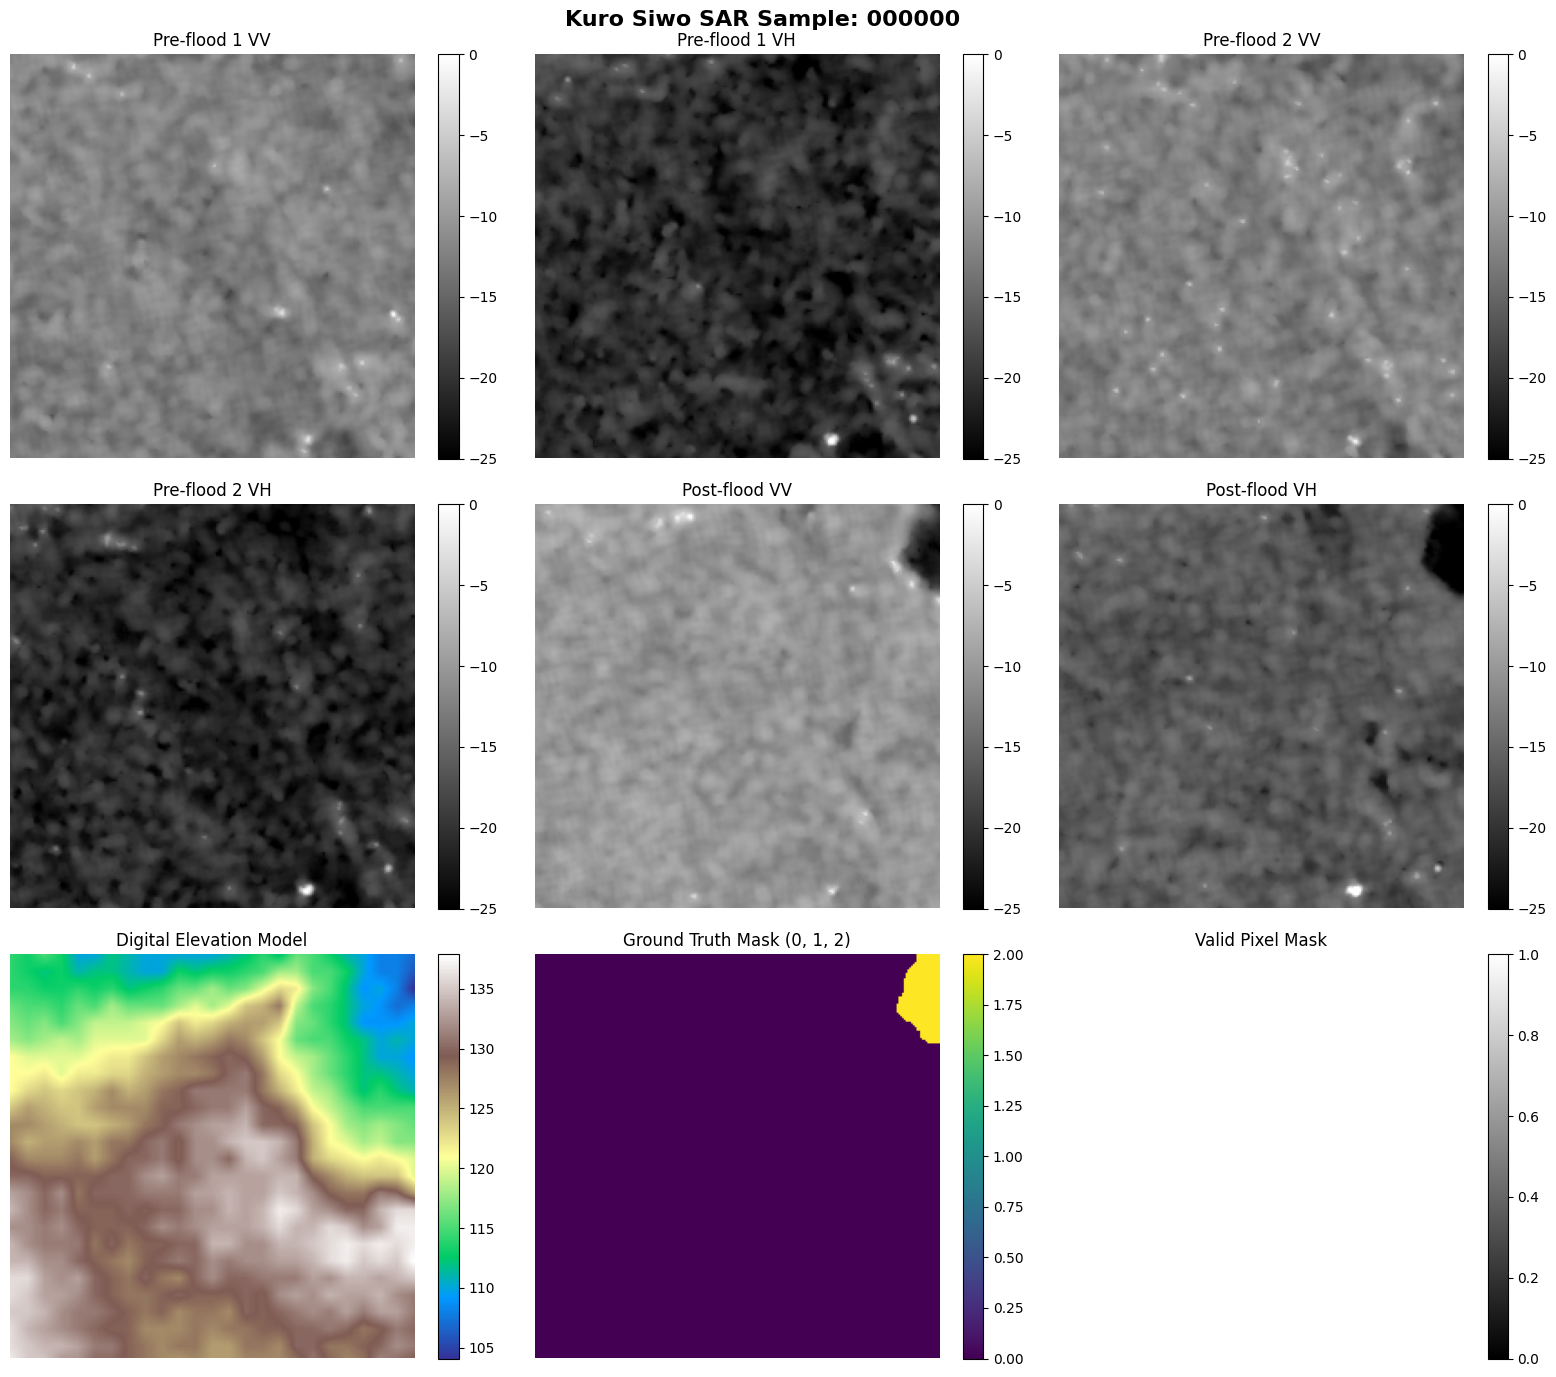

Mask values: [0. 2.]
Valid mask values: [1.]
Valid pixel fraction: 1.0


In [7]:
import tarfile
import io
import numpy as np
import matplotlib.pyplot as plt

SAMPLE_ID = "000000"

sample = {}

with tarfile.open(SHARD_PATH, mode="r:") as tar:
    for member in tar:
        if not member.isfile():
            continue

        filename = member.name.split("/")[-1]

        if not filename.startswith(SAMPLE_ID + "."):
            continue

        field_name = filename[len(SAMPLE_ID) + 1:]

        if field_name.endswith(".npy"):
            field_name = field_name[:-4]

            file_obj = tar.extractfile(member)
            sample[field_name] = np.load(
                io.BytesIO(file_obj.read()),
                allow_pickle=False
            )

# Remove singleton channel dimension
for key in sample:
    sample[key] = np.squeeze(sample[key])

# Convert SAR backscatter from linear scale to dB for visualization
sar_channels = [
    ("sec1_vv", "Pre-flood 1 VV"),
    ("sec1_vh", "Pre-flood 1 VH"),
    ("sec2_vv", "Pre-flood 2 VV"),
    ("sec2_vh", "Pre-flood 2 VH"),
    ("flood_vv", "Post-flood VV"),
    ("flood_vh", "Post-flood VH"),
]

fig, axes = plt.subplots(3, 3, figsize=(16, 14))

for i, (key, title) in enumerate(sar_channels):
    ax = axes.flat[i]

    image = 10 * np.log10(
        np.clip(sample[key], 1e-4, None)
    )

    im = ax.imshow(image, cmap="gray", vmin=-25, vmax=0)
    ax.set_title(title)
    ax.axis("off")
    plt.colorbar(im, ax=ax, fraction=0.046)

# DEM
im = axes.flat[6].imshow(sample["dem"], cmap="terrain")
axes.flat[6].set_title("Digital Elevation Model")
axes.flat[6].axis("off")
plt.colorbar(im, ax=axes.flat[6], fraction=0.046)

# Ground-truth mask
im = axes.flat[7].imshow(
    sample["mask"],
    cmap="viridis",
    vmin=0,
    vmax=2
)
axes.flat[7].set_title("Ground Truth Mask (0, 1, 2)")
axes.flat[7].axis("off")
plt.colorbar(im, ax=axes.flat[7], fraction=0.046)

# Valid pixel mask
im = axes.flat[8].imshow(
    sample["valid_mask"],
    cmap="gray",
    vmin=0,
    vmax=1
)
axes.flat[8].set_title("Valid Pixel Mask")
axes.flat[8].axis("off")
plt.colorbar(im, ax=axes.flat[8], fraction=0.046)

plt.suptitle(
    f"Kuro Siwo SAR Sample: {SAMPLE_ID}",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

print("Mask values:", np.unique(sample["mask"]))
print("Valid mask values:", np.unique(sample["valid_mask"]))
print("Valid pixel fraction:", np.mean(sample["valid_mask"] > 0))

In [8]:
import tarfile
import io
import numpy as np
import pandas as pd

SAMPLE_COUNT = 100

SAR_FIELDS = [
    "sec1_vv",
    "sec1_vh",
    "sec2_vv",
    "sec2_vh",
    "flood_vv",
    "flood_vh",
]

statistics = {
    field: {
        "values": [],
        "zero_count": 0,
        "nonfinite_count": 0,
    }
    for field in SAR_FIELDS
}

valid_pixel_count = 0
total_pixel_count = 0

print(f"Inspecting {SAMPLE_COUNT} samples...")

with tarfile.open(SHARD_PATH, mode="r:") as tar:

    sample_index = 0

    for member in tar:

        if not member.isfile():
            continue

        filename = member.name.split("/")[-1]

        if not filename.endswith(".valid_mask.npy"):
            continue

        if sample_index >= SAMPLE_COUNT:
            break

        sample_id = filename.replace(".valid_mask.npy", "")

        # Load valid pixel mask
        valid_file = tar.extractfile(member)
        valid_mask = np.load(
            io.BytesIO(valid_file.read()),
            allow_pickle=False
        ).squeeze()

        valid = valid_mask > 0

        valid_pixel_count += np.sum(valid)
        total_pixel_count += valid.size

        # Load the six SAR channels for this sample
        for field in SAR_FIELDS:

            target_name = f"{sample_id}.{field}.npy"

            sar_member = next(
                (
                    m for m in tar
                    if m.name.split("/")[-1] == target_name
                ),
                None
            )

            if sar_member is None:
                raise ValueError(f"Missing field: {target_name}")

            sar_file = tar.extractfile(sar_member)

            image = np.load(
                io.BytesIO(sar_file.read()),
                allow_pickle=False
            ).squeeze()

            values = image[valid]

            statistics[field]["zero_count"] += np.sum(values == 0)
            statistics[field]["nonfinite_count"] += np.sum(
                ~np.isfinite(values)
            )

            values = values[np.isfinite(values)]
            statistics[field]["values"].append(values)

        sample_index += 1

# Summarize statistics
rows = []

for field, result in statistics.items():

    values = np.concatenate(result["values"])

    rows.append({
        "Channel": field,
        "Min": np.min(values),
        "Max": np.max(values),
        "Mean": np.mean(values),
        "Std": np.std(values),
        "P1": np.percentile(values, 1),
        "P50": np.percentile(values, 50),
        "P99": np.percentile(values, 99),
        "Zero Pixels": result["zero_count"],
        "Nonfinite Pixels": result["nonfinite_count"],
    })

stats_df = pd.DataFrame(rows)

print("\nSAR CHANNEL STATISTICS")
display(stats_df.round(5))

print("\nVALID PIXEL STATISTICS")
print(f"Samples inspected: {sample_index}")
print(f"Valid pixels: {valid_pixel_count:,}")
print(f"Total pixels: {total_pixel_count:,}")
print(f"Valid pixel percentage: {100 * valid_pixel_count / total_pixel_count:.3f}%")

Inspecting 100 samples...

SAR CHANNEL STATISTICS


,Channel,Min,Max,Mean,Std,P1,P50,P99,Zero Pixels,Nonfinite Pixels
0,sec1_vv,0.00187,17.961121,0.04953,0.05162,0.01115,0.04234,0.16627,0,0
1,sec1_vh,0.00052,2.133480,0.00938,0.00920,0.00175,0.00720,0.04144,0,0
2,sec2_vv,0.00151,17.018070,0.04438,0.04927,0.01051,0.03720,0.16320,0,0
3,sec2_vh,0.00066,1.770830,0.00813,0.00928,0.00157,0.00570,0.04357,0,0
4,flood_vv,0.00132,20.415581,0.10614,0.08574,0.00432,0.10374,0.38833,0,0
5,flood_vh,0.00064,12.238180,0.02376,0.01814,0.00165,0.02516,0.05536,0,0



VALID PIXEL STATISTICS
Samples inspected: 100
Valid pixels: 5,016,114
Total pixels: 5,017,600
Valid pixel percentage: 99.970%


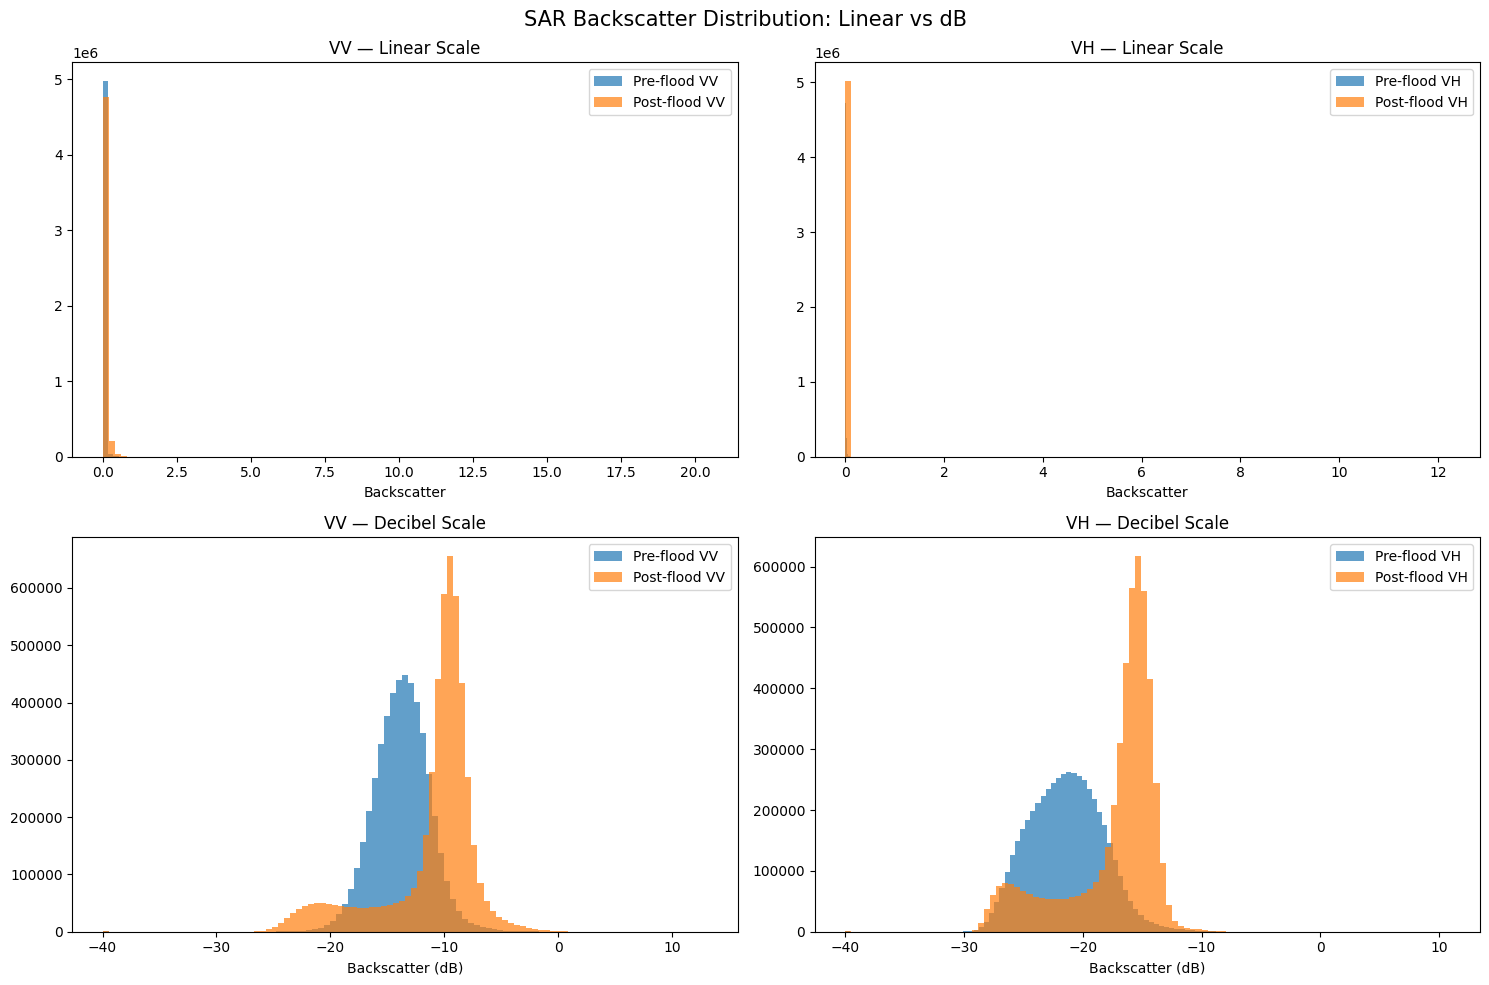

In [9]:
import tarfile
import io
import numpy as np
import matplotlib.pyplot as plt

SAMPLE_COUNT = 100

linear_distributions = {field: [] for field in SAR_FIELDS}
db_distributions = {field: [] for field in SAR_FIELDS}

with tarfile.open(SHARD_PATH, mode="r:") as tar:

    for sample_index in range(SAMPLE_COUNT):

        sample_data = {}

        for field in SAR_FIELDS:

            target_name = f"{sample_index:06d}.{field}.npy"

            member = tar.getmember(target_name)
            file_obj = tar.extractfile(member)

            image = np.load(
                io.BytesIO(file_obj.read()),
                allow_pickle=False
            ).squeeze()

            linear_values = image[np.isfinite(image)]

            db_values = 10 * np.log10(
                np.clip(linear_values, 1e-4, None)
            )

            linear_distributions[field].append(linear_values)
            db_distributions[field].append(db_values)

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Linear-scale VV and VH distributions
axes[0, 0].hist(
    np.concatenate(linear_distributions["sec1_vv"]),
    bins=100,
    alpha=0.7,
    label="Pre-flood VV"
)
axes[0, 0].hist(
    np.concatenate(linear_distributions["flood_vv"]),
    bins=100,
    alpha=0.7,
    label="Post-flood VV"
)
axes[0, 0].set_title("VV — Linear Scale")
axes[0, 0].set_xlabel("Backscatter")
axes[0, 0].legend()

axes[0, 1].hist(
    np.concatenate(linear_distributions["sec1_vh"]),
    bins=100,
    alpha=0.7,
    label="Pre-flood VH"
)
axes[0, 1].hist(
    np.concatenate(linear_distributions["flood_vh"]),
    bins=100,
    alpha=0.7,
    label="Post-flood VH"
)
axes[0, 1].set_title("VH — Linear Scale")
axes[0, 1].set_xlabel("Backscatter")
axes[0, 1].legend()

# dB-scale distributions
axes[1, 0].hist(
    np.concatenate(db_distributions["sec1_vv"]),
    bins=100,
    alpha=0.7,
    label="Pre-flood VV"
)
axes[1, 0].hist(
    np.concatenate(db_distributions["flood_vv"]),
    bins=100,
    alpha=0.7,
    label="Post-flood VV"
)
axes[1, 0].set_title("VV — Decibel Scale")
axes[1, 0].set_xlabel("Backscatter (dB)")
axes[1, 0].legend()

axes[1, 1].hist(
    np.concatenate(db_distributions["sec1_vh"]),
    bins=100,
    alpha=0.7,
    label="Pre-flood VH"
)
axes[1, 1].hist(
    np.concatenate(db_distributions["flood_vh"]),
    bins=100,
    alpha=0.7,
    label="Post-flood VH"
)
axes[1, 1].set_title("VH — Decibel Scale")
axes[1, 1].set_xlabel("Backscatter (dB)")
axes[1, 1].legend()

plt.suptitle("SAR Backscatter Distribution: Linear vs dB", fontsize=15)
plt.tight_layout()
plt.show()

In [11]:
METADATA_PATH = DIRECTORIES["data"] / "shard_00000_metadata.csv"

df_metadata.to_csv(METADATA_PATH, index=False)

print("Metadata saved successfully.")
print(f"Path: {METADATA_PATH}")
print(f"Rows: {len(df_metadata):,}")
print(f"Columns: {len(df_metadata.columns)}")

Metadata saved successfully.
Path: /kaggle/working/flood_mapping_project/data/shard_00000_metadata.csv
Rows: 6,000
Columns: 11


In [12]:
import pandas as pd

# Event-level summary
event_summary = (
    df_metadata
    .groupby("actid")
    .agg(
        sample_count=("sample_id", "count"),
        aoi_count=("aoiid", "nunique"),
        aoi_ids=("aoiid", lambda x: sorted(x.dropna().unique().tolist())),
        flood_date=("flood_date", "first"),
        mean_flood_coverage=("pflood", "mean"),
        median_flood_coverage=("pflood", "median"),
    )
    .reset_index()
    .sort_values("sample_count", ascending=False)
)

print("=" * 75)
print("FLOOD EVENT SUMMARY")
print("=" * 75)

display(event_summary.round(3))

# Event and AOI relationship
event_aoi_table = pd.crosstab(
    df_metadata["actid"],
    df_metadata["aoiid"]
)

print("\n" + "=" * 75)
print("FLOOD EVENT vs AOI DISTRIBUTION")
print("=" * 75)

display(event_aoi_table)

# AOI-level summary
aoi_summary = (
    df_metadata
    .groupby("aoiid")
    .agg(
        sample_count=("sample_id", "count"),
        event_count=("actid", "nunique"),
        event_ids=("actid", lambda x: sorted(x.unique().tolist())),
        mean_flood_coverage=("pflood", "mean"),
    )
    .reset_index()
    .sort_values("sample_count", ascending=False)
)

print("\n" + "=" * 75)
print("AOI SUMMARY")
print("=" * 75)

display(aoi_summary.round(3))

FLOOD EVENT SUMMARY


,actid,sample_count,aoi_count,aoi_ids,flood_date,mean_flood_coverage,median_flood_coverage
16,1111004,3246,1,[1],2017-08-28 08:00:00,7.835,3.709
9,555,684,1,[1],2021-12-10 11:00:00,3.997,0.832
5,502,445,6,"[1, 2, 3, 4, 5, 7]",2021-02-23 04:00:00,3.249,0.498
3,497,398,1,[1],2021-02-01 12:00:00,6.566,0.286
6,518,306,2,"[1, 2]",2021-07-14 20:00:00,2.582,0.326
1,492,213,1,[1],2021-01-01 12:00:00,9.652,3.320
0,470,166,1,[1],2020-10-05 18:00:00,23.701,15.547
4,498,102,1,[1],2021-02-02 00:00:00,1.466,0.000
13,567,96,2,"[8, 15]",2022-02-26 08:00:00,24.290,20.742
7,520,79,1,[1],2021-07-16 00:00:00,8.306,5.056



FLOOD EVENT vs AOI DISTRIBUTION


aoiid,1,2,3,4,5,7,8,13,15
actid,,,,,,,,,
470,166,0,0,0,0,0,0,0,0
492,213,0,0,0,0,0,0,0,0
496,21,0,0,0,0,0,0,0,0
497,398,0,0,0,0,0,0,0,0
498,102,0,0,0,0,0,0,0,0
502,74,31,53,42,225,20,0,0,0
518,166,140,0,0,0,0,0,0,0
520,79,0,0,0,0,0,0,0,0
554,71,0,0,0,0,0,0,0,0



AOI SUMMARY


,aoiid,sample_count,event_count,event_ids,mean_flood_coverage
0,1,5300,14,"[470, 492, 496, 497, 498, 502, 518, 520, 554, ...",7.552
4,5,225,1,[502],1.181
1,2,171,2,"[502, 518]",4.118
3,4,68,2,"[502, 559]",3.373
7,13,67,1,[562],28.896
6,8,66,1,[567],33.798
2,3,53,1,[502],7.230
8,15,30,1,[567],3.373
5,7,20,1,[502],2.948


In [13]:
from collections import defaultdict, deque

# Build event-to-AOI and AOI-to-event relationships
event_to_aois = (
    df_metadata.groupby("actid")["aoiid"]
    .apply(lambda x: set(x.dropna()))
    .to_dict()
)

aoi_to_events = defaultdict(set)

for event, aois in event_to_aois.items():
    for aoi in aois:
        aoi_to_events[aoi].add(event)

# Find connected components in the event-AOI relationship graph
unvisited_events = set(event_to_aois.keys())
components = []

while unvisited_events:

    start_event = unvisited_events.pop()
    component_events = {start_event}
    component_aois = set()

    queue = deque([("event", start_event)])

    while queue:

        node_type, node_id = queue.popleft()

        if node_type == "event":

            for aoi in event_to_aois[node_id]:

                if aoi not in component_aois:
                    component_aois.add(aoi)
                    queue.append(("aoi", aoi))

        else:

            for event in aoi_to_events[node_id]:

                if event not in component_events:
                    component_events.add(event)
                    unvisited_events.discard(event)
                    queue.append(("event", event))

    components.append({
        "events": sorted(component_events),
        "aois": sorted(component_aois),
        "event_count": len(component_events),
        "aoi_count": len(component_aois),
    })

print("=" * 70)
print("CONNECTED EVENT–AOI GROUPS")
print("=" * 70)

for i, component in enumerate(components, start=1):

    print(f"\nGroup {i}")
    print("Events:", component["events"])
    print("AOIs:", component["aois"])
    print("Number of events:", component["event_count"])
    print("Number of AOIs:", component["aoi_count"])

print("\nTotal connected groups:", len(components))

CONNECTED EVENT–AOI GROUPS

Group 1
Events: [567]
AOIs: [8, 15]
Number of events: 1
Number of AOIs: 2

Group 2
Events: [470, 492, 496, 497, 498, 502, 518, 520, 554, 555, 559, 561, 1111002, 1111003, 1111004]
AOIs: [1, 2, 3, 4, 5, 7]
Number of events: 15
Number of AOIs: 6

Group 3
Events: [562]
AOIs: [13]
Number of events: 1
Number of AOIs: 1

Total connected groups: 3


In [14]:
from huggingface_hub import HfApi

api = HfApi()

repo_id = "orion-ai-lab/Kuro-Siwo-Webdataset"

files = api.list_repo_files(
    repo_id=repo_id,
    repo_type="dataset"
)

remaining_shards = [
    f for f in files
    if f.startswith("train_GRD/")
    and f.endswith(".tar")
    and f != "train_GRD/shard-00000.tar"
]

print("=" * 65)
print("REMAINING TRAINING SHARDS")
print("=" * 65)

for shard in remaining_shards:
    info = api.hf_hub_download if False else None
    print(shard)

print("\nTotal remaining shards:", len(remaining_shards))
print("\nLocal disk space:")

import shutil

usage = shutil.disk_usage("/kaggle/working")

print(f"Total: {usage.total / 1024**3:.2f} GB")
print(f"Used : {usage.used / 1024**3:.2f} GB")
print(f"Free : {usage.free / 1024**3:.2f} GB")

REMAINING TRAINING SHARDS
train_GRD/shard-00001.tar
train_GRD/shard-00002.tar
train_GRD/shard-00003.tar
train_GRD/shard-00004.tar

Total remaining shards: 4

Local disk space:
Total: 19.52 GB
Used : 10.17 GB
Free : 9.34 GB


In [15]:
from huggingface_hub import HfApi

api = HfApi()

repo_id = "orion-ai-lab/Kuro-Siwo-Webdataset"

shard_info = api.get_paths_info(
    repo_id=repo_id,
    paths=remaining_shards,
    repo_type="dataset"
)

shard_inventory = []

for item in shard_info:
    size_gb = item.size / (1024 ** 3)

    shard_inventory.append({
        "Shard": item.path,
        "Size (GB)": round(size_gb, 2),
        "Size (MB)": round(item.size / (1024 ** 2), 2),
    })

inventory_df = pd.DataFrame(shard_inventory)

print("REMOTE TRAINING SHARD INVENTORY")
display(inventory_df)

print(
    "\nTotal remaining size:",
    round(inventory_df["Size (GB)"].sum(), 2),
    "GB"
)

REMOTE TRAINING SHARD INVENTORY


,Shard,Size (GB),Size (MB)
0,train_GRD/shard-00001.tar,10.17,10409.30
1,train_GRD/shard-00002.tar,10.17,10409.26
2,train_GRD/shard-00003.tar,10.17,10409.26
3,train_GRD/shard-00004.tar,2.89,2961.43



Total remaining size: 33.4 GB


In [16]:
from huggingface_hub import hf_hub_download
import os

SHARD_4_PATH = hf_hub_download(
    repo_id="orion-ai-lab/Kuro-Siwo-Webdataset",
    filename="train_GRD/shard-00004.tar",
    repo_type="dataset",
    local_dir=str(DIRECTORIES["data"] / "kuro_siwo")
)

SHARD_4_PATH = Path(SHARD_4_PATH)

print("=" * 60)
print("SHARD 00004 DOWNLOAD")
print("=" * 60)

print("Path:", SHARD_4_PATH)
print(f"Size: {SHARD_4_PATH.stat().st_size / (1024**3):.2f} GB")

usage = shutil.disk_usage("/kaggle/working")
print(f"Remaining disk space: {usage.free / (1024**3):.2f} GB")

train_GRD/shard-00004.tar: reconstructing file:   0%|          |  0.00B / 3.11GB            

train_GRD/shard-00004.tar: downloading bytes:           |  0.00B            

SHARD 00004 DOWNLOAD
Path: /kaggle/working/flood_mapping_project/data/kuro_siwo/train_GRD/shard-00004.tar
Size: 2.89 GB
Remaining disk space: 6.44 GB


In [17]:
import tarfile
import json
import pandas as pd

metadata_records_4 = []

print("Reading metadata from training shard 00004...")

with tarfile.open(SHARD_4_PATH, mode="r:") as tar:

    for member in tar:

        if not member.isfile() or not member.name.endswith(".info.json"):
            continue

        file_obj = tar.extractfile(member)

        if file_obj is None:
            continue

        info = json.loads(file_obj.read().decode("utf-8"))

        metadata_records_4.append({
            "sample_id": member.name.split("/")[-1].replace(".info.json", ""),
            "actid": info.get("actid"),
            "aoiid": info.get("aoiid"),
            "flood_date": info.get("flood_date"),
            "pflood": info.get("pflood"),
            "pwater": info.get("pwater"),
            "pcovered": info.get("pcovered"),
            "gvalid": info.get("gvalid"),
            "sl1_date": info.get("sources", {}).get("SL1", {}).get("source_date"),
            "sl2_date": info.get("sources", {}).get("SL2", {}).get("source_date"),
            "post_date": info.get("sources", {}).get("MS1", {}).get("source_date"),
        })

df_metadata_4 = pd.DataFrame(metadata_records_4)

print("\n" + "=" * 65)
print("SHARD 00004 SUMMARY")
print("=" * 65)

print(f"Total samples: {len(df_metadata_4):,}")
print(f"Unique flood events: {df_metadata_4['actid'].nunique()}")
print(f"Unique AOIs: {df_metadata_4['aoiid'].nunique()}")

print("\nSamples per flood event:")
print(df_metadata_4["actid"].value_counts().sort_index().to_string())

print("\nSamples per AOI:")
print(df_metadata_4["aoiid"].value_counts().sort_index().to_string())

print("\nFlood coverage statistics:")
print(df_metadata_4["pflood"].describe().round(3))

print("\nMetadata extraction completed.")

Reading metadata from training shard 00004...

SHARD 00004 SUMMARY
Total samples: 1,707
Unique flood events: 1
Unique AOIs: 1

Samples per flood event:
actid
1111013    1707

Samples per AOI:
aoiid
1    1707

Flood coverage statistics:
count    1707.000
mean        5.133
std        10.009
min         0.000
25%         0.000
50%         0.875
75%         5.434
max        96.060
Name: pflood, dtype: float64

Metadata extraction completed.


In [18]:
# Add shard identifiers
df_metadata["shard"] = "00000"
df_metadata_4["shard"] = "00004"

# Combine inspected shard metadata
df_inspected = pd.concat(
    [df_metadata, df_metadata_4],
    ignore_index=True
)

print("=" * 65)
print("COMBINED DATASET SUMMARY")
print("=" * 65)

print("Total samples:", len(df_inspected))
print("Unique events:", df_inspected["actid"].nunique())
print("Unique AOIs:", df_inspected["aoiid"].nunique())

print("\nSamples per shard:")
print(df_inspected["shard"].value_counts().sort_index())

print("\nSamples per event:")
print(
    df_inspected.groupby("actid")
    .size()
    .sort_values(ascending=False)
    .to_string()
)

print("\nEvents appearing in both shards:")

event_overlap = (
    set(df_metadata["actid"].unique())
    & set(df_metadata_4["actid"].unique())
)

print(sorted(event_overlap) if event_overlap else "None")

# Save combined metadata
COMBINED_METADATA_PATH = (
    DIRECTORIES["data"] / "inspected_training_metadata.csv"
)

df_inspected.to_csv(COMBINED_METADATA_PATH, index=False)

print("\nSaved:", COMBINED_METADATA_PATH)

COMBINED DATASET SUMMARY
Total samples: 7707
Unique events: 18
Unique AOIs: 9

Samples per shard:
shard
00000    6000
00004    1707
Name: count, dtype: int64

Samples per event:
actid
1111004    3246
1111013    1707
555         684
502         445
497         398
518         306
492         213
470         166
498         102
567          96
520          79
554          71
562          67
561          38
1111002      29
559          26
496          21
1111003      13

Events appearing in both shards:
None

Saved: /kaggle/working/flood_mapping_project/data/inspected_training_metadata.csv


In [19]:
import shutil
from pathlib import Path

# Files to remove
tar_files = [
    SHARD_PATH,
    SHARD_4_PATH,
]

# Metadata files that must be preserved
metadata_files = [
    METADATA_PATH,
    COMBINED_METADATA_PATH,
]

print("=" * 65)
print("PRE-DELETION VERIFICATION")
print("=" * 65)

for path in metadata_files:
    assert path.exists(), f"Metadata missing: {path}"
    print(f"Preserved: {path.name} ({path.stat().st_size / 1024:.2f} KB)")

assert len(df_inspected) == 7707
assert df_inspected["actid"].nunique() == 18

print("\nMetadata verification successful.")

# Delete TAR archives
print("\nDeleting downloaded TAR archives...")

for path in tar_files:
    path = Path(path)

    if path.exists():
        size_gb = path.stat().st_size / (1024 ** 3)
        path.unlink()
        print(f"Deleted: {path.name} ({size_gb:.2f} GB)")
    else:
        print(f"Already absent: {path.name}")

# Verify metadata remains
for path in metadata_files:
    assert path.exists(), f"Preserved metadata unexpectedly missing: {path}"

# Disk space after deletion
usage = shutil.disk_usage("/kaggle/working")

print("\n" + "=" * 65)
print("STORAGE AFTER CLEANUP")
print("=" * 65)

print(f"Free space: {usage.free / (1024**3):.2f} GB")
print(f"Used space: {usage.used / (1024**3):.2f} GB")

print("\nCleanup completed successfully.")

PRE-DELETION VERIFICATION
Preserved: shard_00000_metadata.csv (629.16 KB)
Preserved: inspected_training_metadata.csv (858.57 KB)

Metadata verification successful.

Deleting downloaded TAR archives...
Deleted: shard-00000.tar (10.17 GB)
Deleted: shard-00004.tar (2.89 GB)

STORAGE AFTER CLEANUP
Free space: 19.50 GB
Used space: 0.00 GB

Cleanup completed successfully.


In [20]:
from huggingface_hub import hf_hub_download
from pathlib import Path
import shutil

SHARD_1_PATH = hf_hub_download(
    repo_id="orion-ai-lab/Kuro-Siwo-Webdataset",
    filename="train_GRD/shard-00001.tar",
    repo_type="dataset",
    local_dir=str(DIRECTORIES["data"] / "kuro_siwo")
)

SHARD_1_PATH = Path(SHARD_1_PATH)

usage = shutil.disk_usage("/kaggle/working")

print("=" * 65)
print("SHARD 00001 DOWNLOAD")
print("=" * 65)

print("Path:", SHARD_1_PATH)
print(f"Downloaded size: {SHARD_1_PATH.stat().st_size / (1024**3):.2f} GB")
print(f"Free disk space: {usage.free / (1024**3):.2f} GB")

assert SHARD_1_PATH.exists()

train_GRD/shard-00001.tar: reconstructing file:   0%|          |  0.00B / 10.9GB            

train_GRD/shard-00001.tar: downloading bytes:           |  0.00B            

SHARD 00001 DOWNLOAD
Path: /kaggle/working/flood_mapping_project/data/kuro_siwo/train_GRD/shard-00001.tar
Downloaded size: 10.17 GB
Free disk space: 9.34 GB


In [21]:
import tarfile
import json
import pandas as pd

metadata_records_1 = []

print("Reading metadata from training shard 00001...")

with tarfile.open(SHARD_1_PATH, mode="r:") as tar:

    for member in tar:

        if not member.isfile() or not member.name.endswith(".info.json"):
            continue

        file_obj = tar.extractfile(member)

        if file_obj is None:
            continue

        info = json.loads(file_obj.read().decode("utf-8"))

        metadata_records_1.append({
            "sample_id": member.name.split("/")[-1].replace(".info.json", ""),
            "actid": info.get("actid"),
            "aoiid": info.get("aoiid"),
            "flood_date": info.get("flood_date"),
            "pflood": info.get("pflood"),
            "pwater": info.get("pwater"),
            "pcovered": info.get("pcovered"),
            "gvalid": info.get("gvalid"),
            "sl1_date": info.get("sources", {}).get("SL1", {}).get("source_date"),
            "sl2_date": info.get("sources", {}).get("SL2", {}).get("source_date"),
            "post_date": info.get("sources", {}).get("MS1", {}).get("source_date"),
        })

df_metadata_1 = pd.DataFrame(metadata_records_1)

print("\n" + "=" * 65)
print("SHARD 00001 SUMMARY")
print("=" * 65)

print(f"Total samples: {len(df_metadata_1):,}")
print(f"Unique flood events: {df_metadata_1['actid'].nunique()}")
print(f"Unique AOIs: {df_metadata_1['aoiid'].nunique()}")

print("\nSamples per flood event:")
print(df_metadata_1["actid"].value_counts().sort_index().to_string())

print("\nSamples per AOI:")
print(df_metadata_1["aoiid"].value_counts().sort_index().to_string())

print("\nFlood coverage statistics:")
print(df_metadata_1["pflood"].describe().round(3))

# Save metadata
df_metadata_1["shard"] = "00001"

SHARD_1_METADATA_PATH = (
    DIRECTORIES["data"] / "shard_00001_metadata.csv"
)

df_metadata_1.to_csv(SHARD_1_METADATA_PATH, index=False)

print("\nMetadata saved:", SHARD_1_METADATA_PATH)
print("Metadata extraction completed.")

Reading metadata from training shard 00001...

SHARD 00001 SUMMARY
Total samples: 6,000
Unique flood events: 6
Unique AOIs: 1

Samples per flood event:
actid
1111004     840
1111005     620
1111006     313
1111007    2329
1111008      81
1111009    1817

Samples per AOI:
aoiid
1    6000

Flood coverage statistics:
count    6000.000
mean       19.647
std        26.525
min         0.000
25%         0.513
50%         6.579
75%        29.744
max       100.000
Name: pflood, dtype: float64

Metadata saved: /kaggle/working/flood_mapping_project/data/shard_00001_metadata.csv
Metadata extraction completed.


In [22]:
# Compare event IDs
previous_events = set(df_inspected["actid"].unique())
new_events = set(df_metadata_1["actid"].unique())

overlapping_events = previous_events & new_events
new_event_ids = new_events - previous_events

print("=" * 65)
print("SHARD 00001 EVENT OVERLAP ANALYSIS")
print("=" * 65)

print("Overlapping events:", sorted(overlapping_events))
print("New events:", sorted(new_event_ids))

# Combine metadata
df_inspected = pd.concat(
    [df_inspected, df_metadata_1],
    ignore_index=True
)

print("\n" + "=" * 65)
print("UPDATED TRAINING METADATA")
print("=" * 65)

print(f"Total samples: {len(df_inspected):,}")
print(f"Unique flood events: {df_inspected['actid'].nunique()}")
print(f"Unique AOIs: {df_inspected['aoiid'].nunique()}")

print("\nSamples per shard:")
print(df_inspected["shard"].value_counts().sort_index())

print("\nSamples per flood event:")
print(
    df_inspected.groupby("actid")
    .size()
    .sort_values(ascending=False)
    .to_string()
)

# Save updated metadata
df_inspected.to_csv(
    DIRECTORIES["data"] / "inspected_training_metadata.csv",
    index=False
)

print("\nUpdated metadata saved successfully.")

SHARD 00001 EVENT OVERLAP ANALYSIS
Overlapping events: [np.int64(1111004)]
New events: [np.int64(1111005), np.int64(1111006), np.int64(1111007), np.int64(1111008), np.int64(1111009)]

UPDATED TRAINING METADATA
Total samples: 13,707
Unique flood events: 23
Unique AOIs: 9

Samples per shard:
shard
00000    6000
00001    6000
00004    1707
Name: count, dtype: int64

Samples per flood event:
actid
1111004    4086
1111007    2329
1111009    1817
1111013    1707
555         684
1111005     620
502         445
497         398
1111006     313
518         306
492         213
470         166
498         102
567          96
1111008      81
520          79
554          71
562          67
561          38
1111002      29
559          26
496          21
1111003      13

Updated metadata saved successfully.


In [23]:
import shutil

print("Verifying metadata...")
assert (DIRECTORIES["data"] / "shard_00001_metadata.csv").exists()
assert len(df_inspected) == 13707

print("Metadata verified.")

if SHARD_1_PATH.exists():
    size_gb = SHARD_1_PATH.stat().st_size / (1024**3)
    SHARD_1_PATH.unlink()
    print(f"Deleted shard 00001: {size_gb:.2f} GB")

usage = shutil.disk_usage("/kaggle/working")

print(f"Free disk space: {usage.free / (1024**3):.2f} GB")

Verifying metadata...
Metadata verified.
Deleted shard 00001: 10.17 GB
Free disk space: 19.50 GB


In [24]:
import tarfile
import json
import pandas as pd
import shutil
from pathlib import Path
from huggingface_hub import hf_hub_download

# --------------------------------------------------
# 1. DOWNLOAD SHARD 00002
# --------------------------------------------------

print("=" * 70)
print("STEP 1: DOWNLOADING SHARD 00002")
print("=" * 70)

SHARD_2_PATH = Path(hf_hub_download(
    repo_id="orion-ai-lab/Kuro-Siwo-Webdataset",
    filename="train_GRD/shard-00002.tar",
    repo_type="dataset",
    local_dir=str(DIRECTORIES["data"] / "kuro_siwo")
))

print(f"Downloaded: {SHARD_2_PATH}")
print(f"Size: {SHARD_2_PATH.stat().st_size / (1024**3):.2f} GB")


# --------------------------------------------------
# 2. EXTRACT METADATA
# --------------------------------------------------

print("\n" + "=" * 70)
print("STEP 2: EXTRACTING METADATA")
print("=" * 70)

metadata_records_2 = []

with tarfile.open(SHARD_2_PATH, mode="r:") as tar:

    for member in tar:

        if not member.isfile() or not member.name.endswith(".info.json"):
            continue

        file_obj = tar.extractfile(member)

        if file_obj is None:
            continue

        info = json.loads(file_obj.read().decode("utf-8"))

        metadata_records_2.append({
            "sample_id": member.name.split("/")[-1].replace(".info.json", ""),
            "actid": info.get("actid"),
            "aoiid": info.get("aoiid"),
            "flood_date": info.get("flood_date"),
            "pflood": info.get("pflood"),
            "pwater": info.get("pwater"),
            "pcovered": info.get("pcovered"),
            "gvalid": info.get("gvalid"),
            "sl1_date": info.get("sources", {}).get("SL1", {}).get("source_date"),
            "sl2_date": info.get("sources", {}).get("SL2", {}).get("source_date"),
            "post_date": info.get("sources", {}).get("MS1", {}).get("source_date"),
        })

df_metadata_2 = pd.DataFrame(metadata_records_2)
df_metadata_2["shard"] = "00002"

print(f"Total samples: {len(df_metadata_2):,}")
print(f"Unique events: {df_metadata_2['actid'].nunique()}")
print(f"Unique AOIs: {df_metadata_2['aoiid'].nunique()}")


# --------------------------------------------------
# 3. EVENT OVERLAP ANALYSIS
# --------------------------------------------------

print("\n" + "=" * 70)
print("STEP 3: EVENT OVERLAP ANALYSIS")
print("=" * 70)

previous_events = set(df_inspected["actid"].unique())
new_events = set(df_metadata_2["actid"].unique())

overlapping_events = previous_events & new_events
new_event_ids = new_events - previous_events

print("Overlapping events:", sorted(overlapping_events))
print("New events:", sorted(new_event_ids))


# --------------------------------------------------
# 4. COMBINE METADATA
# --------------------------------------------------

df_inspected = pd.concat(
    [df_inspected, df_metadata_2],
    ignore_index=True
)

# Save individual shard metadata
SHARD_2_METADATA_PATH = (
    DIRECTORIES["data"] / "shard_00002_metadata.csv"
)

df_metadata_2.to_csv(SHARD_2_METADATA_PATH, index=False)

# Save combined metadata
COMBINED_METADATA_PATH = (
    DIRECTORIES["data"] / "inspected_training_metadata.csv"
)

df_inspected.to_csv(COMBINED_METADATA_PATH, index=False)

print("\n" + "=" * 70)
print("STEP 4: UPDATED DATASET SUMMARY")
print("=" * 70)

print(f"Total samples: {len(df_inspected):,}")
print(f"Unique events: {df_inspected['actid'].nunique()}")
print(f"Unique AOIs: {df_inspected['aoiid'].nunique()}")

print("\nSamples per shard:")
print(df_inspected["shard"].value_counts().sort_index())

print("\nSamples per event:")
print(df_inspected.groupby("actid").size().sort_values(ascending=False))


# --------------------------------------------------
# 5. DELETE TAR AFTER VERIFYING METADATA
# --------------------------------------------------

print("\n" + "=" * 70)
print("STEP 5: STORAGE CLEANUP")
print("=" * 70)

assert len(df_metadata_2) > 0
assert SHARD_2_METADATA_PATH.exists()
assert COMBINED_METADATA_PATH.exists()

SHARD_2_PATH.unlink()

print("Shard 00002 TAR deleted.")
print("Individual metadata preserved.")
print("Combined metadata preserved.")

usage = shutil.disk_usage("/kaggle/working")

print(f"\nRemaining disk space: {usage.free / (1024**3):.2f} GB")
print("\nSHARD 00002 PROCESSING COMPLETED.")

STEP 1: DOWNLOADING SHARD 00002


train_GRD/shard-00002.tar: reconstructing file:   0%|          |  0.00B / 10.9GB            

train_GRD/shard-00002.tar: downloading bytes:           |  0.00B            

Downloaded: /kaggle/working/flood_mapping_project/data/kuro_siwo/train_GRD/shard-00002.tar
Size: 10.17 GB

STEP 2: EXTRACTING METADATA
Total samples: 6,000
Unique events: 2
Unique AOIs: 1

STEP 3: EVENT OVERLAP ANALYSIS
Overlapping events: [np.int64(1111009)]
New events: [np.int64(1111010)]

STEP 4: UPDATED DATASET SUMMARY
Total samples: 19,707
Unique events: 24
Unique AOIs: 9

Samples per shard:
shard
00000    6000
00001    6000
00002    6000
00004    1707
Name: count, dtype: int64

Samples per event:
actid
1111009    7556
1111004    4086
1111007    2329
1111013    1707
555         684
1111005     620
502         445
497         398
1111006     313
518         306
1111010     261
492         213
470         166
498         102
567          96
1111008      81
520          79
554          71
562          67
561          38
1111002      29
559          26
496          21
1111003      13
dtype: int64

STEP 5: STORAGE CLEANUP
Shard 00002 TAR deleted.
Individual metadata preserved.
Combined

In [25]:
import tarfile
import json
import pandas as pd
import shutil
from pathlib import Path
from huggingface_hub import hf_hub_download

# ==================================================
# 1. DOWNLOAD SHARD 00003
# ==================================================

print("=" * 70)
print("STEP 1: DOWNLOADING SHARD 00003")
print("=" * 70)

SHARD_3_PATH = Path(hf_hub_download(
    repo_id="orion-ai-lab/Kuro-Siwo-Webdataset",
    filename="train_GRD/shard-00003.tar",
    repo_type="dataset",
    local_dir=str(DIRECTORIES["data"] / "kuro_siwo")
))

print("Downloaded:", SHARD_3_PATH)
print(f"Size: {SHARD_3_PATH.stat().st_size / (1024**3):.2f} GB")


# ==================================================
# 2. EXTRACT METADATA
# ==================================================

print("\n" + "=" * 70)
print("STEP 2: EXTRACTING METADATA")
print("=" * 70)

metadata_records_3 = []

with tarfile.open(SHARD_3_PATH, mode="r:") as tar:

    for member in tar:

        if not member.isfile() or not member.name.endswith(".info.json"):
            continue

        file_obj = tar.extractfile(member)

        if file_obj is None:
            continue

        info = json.loads(file_obj.read().decode("utf-8"))

        metadata_records_3.append({
            "sample_id": member.name.split("/")[-1].replace(".info.json", ""),
            "actid": info.get("actid"),
            "aoiid": info.get("aoiid"),
            "flood_date": info.get("flood_date"),
            "pflood": info.get("pflood"),
            "pwater": info.get("pwater"),
            "pcovered": info.get("pcovered"),
            "gvalid": info.get("gvalid"),
            "sl1_date": info.get("sources", {}).get("SL1", {}).get("source_date"),
            "sl2_date": info.get("sources", {}).get("SL2", {}).get("source_date"),
            "post_date": info.get("sources", {}).get("MS1", {}).get("source_date"),
        })

df_metadata_3 = pd.DataFrame(metadata_records_3)
df_metadata_3["shard"] = "00003"

print(f"Total samples: {len(df_metadata_3):,}")
print(f"Unique events: {df_metadata_3['actid'].nunique()}")
print(f"Unique AOIs: {df_metadata_3['aoiid'].nunique()}")


# ==================================================
# 3. EVENT OVERLAP ANALYSIS
# ==================================================

print("\n" + "=" * 70)
print("STEP 3: EVENT OVERLAP ANALYSIS")
print("=" * 70)

previous_events = set(df_inspected["actid"].unique())
new_events = set(df_metadata_3["actid"].unique())

overlapping_events = previous_events & new_events
new_event_ids = new_events - previous_events

print("Overlapping events:", sorted(overlapping_events))
print("New events:", sorted(new_event_ids))


# ==================================================
# 4. COMBINE AND SAVE METADATA
# ==================================================

print("\n" + "=" * 70)
print("STEP 4: COMBINING METADATA")
print("=" * 70)

df_inspected = pd.concat(
    [df_inspected, df_metadata_3],
    ignore_index=True
)

SHARD_3_METADATA_PATH = (
    DIRECTORIES["data"] / "shard_00003_metadata.csv"
)

COMBINED_METADATA_PATH = (
    DIRECTORIES["data"] / "inspected_training_metadata.csv"
)

df_metadata_3.to_csv(SHARD_3_METADATA_PATH, index=False)
df_inspected.to_csv(COMBINED_METADATA_PATH, index=False)

print(f"Total samples: {len(df_inspected):,}")
print(f"Unique events: {df_inspected['actid'].nunique()}")
print(f"Unique AOIs: {df_inspected['aoiid'].nunique()}")

print("\nSamples per shard:")
print(df_inspected["shard"].value_counts().sort_index())

print("\nSamples per event:")
print(
    df_inspected.groupby("actid")
    .size()
    .sort_values(ascending=False)
    .to_string()
)


# ==================================================
# 5. VERIFY AND DELETE TAR
# ==================================================

print("\n" + "=" * 70)
print("STEP 5: STORAGE CLEANUP")
print("=" * 70)

assert len(df_metadata_3) > 0
assert SHARD_3_METADATA_PATH.exists()
assert COMBINED_METADATA_PATH.exists()

SHARD_3_PATH.unlink()

print("Shard 00003 TAR deleted.")
print("Individual metadata preserved.")
print("Combined metadata preserved.")

usage = shutil.disk_usage("/kaggle/working")

print(f"Remaining disk space: {usage.free / (1024**3):.2f} GB")

print("\nSHARD 00003 PROCESSING COMPLETED.")

STEP 1: DOWNLOADING SHARD 00003


train_GRD/shard-00003.tar: reconstructing file:   0%|          |  0.00B / 10.9GB            

train_GRD/shard-00003.tar: downloading bytes:           |  0.00B            

Downloaded: /kaggle/working/flood_mapping_project/data/kuro_siwo/train_GRD/shard-00003.tar
Size: 10.17 GB

STEP 2: EXTRACTING METADATA
Total samples: 6,000
Unique events: 3
Unique AOIs: 1

STEP 3: EVENT OVERLAP ANALYSIS
Overlapping events: [np.int64(1111010), np.int64(1111013)]
New events: [np.int64(1111011)]

STEP 4: COMBINING METADATA
Total samples: 25,707
Unique events: 25
Unique AOIs: 9

Samples per shard:
shard
00000    6000
00001    6000
00002    6000
00003    6000
00004    1707
Name: count, dtype: int64

Samples per event:
actid
1111009    7556
1111013    6008
1111004    4086
1111007    2329
1111011    1619
555         684
1111005     620
502         445
497         398
1111010     341
1111006     313
518         306
492         213
470         166
498         102
567          96
1111008      81
520          79
554          71
562          67
561          38
1111002      29
559          26
496          21
1111003      13

STEP 5: STORAGE CLEANUP
Shard 00003 TAR deleted.
Individu

In [26]:
import pandas as pd
import numpy as np

print("=" * 75)
print("FINAL TRAINING DATASET AUDIT")
print("=" * 75)

# 1. Load saved combined metadata
metadata_path = (
    DIRECTORIES["data"] / "inspected_training_metadata.csv"
)

df_inspected = pd.read_csv(metadata_path)

# 2. Expected shard counts
expected_counts = {
    "00000": 6000,
    "00001": 6000,
    "00002": 6000,
    "00003": 6000,
    "00004": 1707,
}

df_inspected["shard"] = (
    df_inspected["shard"].astype(str).str.zfill(5)
)

print("\n1. SHARD VALIDATION")

actual_counts = df_inspected["shard"].value_counts().to_dict()

for shard, expected in expected_counts.items():

    actual = actual_counts.get(shard, 0)
    status = "PASS" if actual == expected else "FAIL"

    print(
        f"Shard {shard}: "
        f"{actual:,} / {expected:,} samples - {status}"
    )

assert actual_counts == expected_counts

# 3. Sample identifier validation
print("\n2. SAMPLE IDENTIFIER VALIDATION")

duplicate_samples = df_inspected.duplicated(
    subset=["shard", "sample_id"]
).sum()

print("Duplicate sample IDs within shards:", duplicate_samples)

assert duplicate_samples == 0

# 4. Dataset totals
print("\n3. DATASET TOTALS")

print("Total samples:", len(df_inspected))
print("Unique flood events:", df_inspected["actid"].nunique())
print("Unique AOIs:", df_inspected["aoiid"].nunique())

assert len(df_inspected) == 25707
assert df_inspected["actid"].nunique() == 25

# 5. Missing values
print("\n4. MISSING METADATA VALUES")

print(df_inspected.isnull().sum().to_string())

# 6. Event distribution
print("\n5. EVENT DISTRIBUTION")

event_summary = (
    df_inspected.groupby("actid")
    .agg(
        samples=("sample_id", "count"),
        aoi_count=("aoiid", "nunique"),
        mean_flood=("pflood", "mean"),
        median_flood=("pflood", "median"),
    )
    .sort_values("samples", ascending=False)
)

display(event_summary.round(3))

# 7. AOI distribution
print("\n6. AOI DISTRIBUTION")

aoi_summary = (
    df_inspected.groupby("aoiid")
    .agg(
        samples=("sample_id", "count"),
        event_count=("actid", "nunique"),
    )
    .sort_values("samples", ascending=False)
)

display(aoi_summary)

# 8. Flood coverage
print("\n7. FLOOD COVERAGE")

print(df_inspected["pflood"].describe().round(3))

# 9. Save validated metadata
df_inspected.to_csv(metadata_path, index=False)

print("\n" + "=" * 75)
print("FINAL METADATA AUDIT COMPLETED")
print("=" * 75)

FINAL TRAINING DATASET AUDIT

1. SHARD VALIDATION
Shard 00000: 6,000 / 6,000 samples - PASS
Shard 00001: 6,000 / 6,000 samples - PASS
Shard 00002: 6,000 / 6,000 samples - PASS
Shard 00003: 6,000 / 6,000 samples - PASS
Shard 00004: 1,707 / 1,707 samples - PASS

2. SAMPLE IDENTIFIER VALIDATION
Duplicate sample IDs within shards: 0

3. DATASET TOTALS
Total samples: 25707
Unique flood events: 25
Unique AOIs: 9

4. MISSING METADATA VALUES
sample_id     0
actid         0
aoiid         0
flood_date    0
pflood        0
pwater        0
pcovered      0
gvalid        0
sl1_date      0
sl2_date      0
post_date     0
shard         0

5. EVENT DISTRIBUTION


,samples,aoi_count,mean_flood,median_flood
actid,,,,
1111009,7556,1,31.277,20.982
1111013,6008,1,5.314,0.922
1111004,4086,1,7.875,3.657
1111007,2329,1,11.766,1.170
1111011,1619,1,12.974,2.322
555,684,1,3.997,0.832
1111005,620,1,32.808,20.113
502,445,6,3.249,0.498
497,398,1,6.566,0.286



6. AOI DISTRIBUTION


,samples,event_count
aoiid,,
1,25007,22
5,225,1
2,171,2
4,68,2
13,67,1
8,66,1
3,53,1
15,30,1
7,20,1



7. FLOOD COVERAGE
count    25707.000
mean        15.771
std         23.765
min          0.000
25%          0.409
50%          4.393
75%         20.204
max        100.000
Name: pflood, dtype: float64

FINAL METADATA AUDIT COMPLETED


In [27]:
from collections import defaultdict, deque

# Build event-to-AOI relationships
event_to_aois = (
    df_inspected.groupby("actid")["aoiid"]
    .apply(lambda x: set(x.dropna()))
    .to_dict()
)

# Build AOI-to-event relationships
aoi_to_events = defaultdict(set)

for event, aois in event_to_aois.items():
    for aoi in aois:
        aoi_to_events[aoi].add(event)

# Find connected components
unvisited_events = set(event_to_aois.keys())
components = []

while unvisited_events:

    start_event = unvisited_events.pop()

    component_events = {start_event}
    component_aois = set()

    queue = deque([("event", start_event)])

    while queue:

        node_type, node_id = queue.popleft()

        if node_type == "event":

            for aoi in event_to_aois[node_id]:

                if aoi not in component_aois:
                    component_aois.add(aoi)
                    queue.append(("aoi", aoi))

        else:

            for event in aoi_to_events[node_id]:

                if event not in component_events:
                    component_events.add(event)
                    unvisited_events.discard(event)
                    queue.append(("event", event))

    component_samples = df_inspected[
        df_inspected["actid"].isin(component_events)
    ]

    components.append({
        "events": sorted(component_events),
        "aois": sorted(component_aois),
        "event_count": len(component_events),
        "aoi_count": len(component_aois),
        "sample_count": len(component_samples),
    })

print("=" * 75)
print("COMPLETE TRAINING DATA: EVENT–AOI CONNECTIVITY")
print("=" * 75)

for i, component in enumerate(components, start=1):

    print(f"\nGROUP {i}")
    print("Events:", component["events"])
    print("AOIs:", component["aois"])
    print("Event count:", component["event_count"])
    print("AOI count:", component["aoi_count"])
    print("Sample count:", component["sample_count"])

print("\nTotal connected groups:", len(components))

COMPLETE TRAINING DATA: EVENT–AOI CONNECTIVITY

GROUP 1
Events: [470, 492, 496, 497, 498, 502, 518, 520, 554, 555, 559, 561, 1111002, 1111003, 1111004, 1111005, 1111006, 1111007, 1111008, 1111009, 1111010, 1111011, 1111013]
AOIs: [1, 2, 3, 4, 5, 7]
Event count: 23
AOI count: 6
Sample count: 25544

GROUP 2
Events: [562]
AOIs: [13]
Event count: 1
AOI count: 1
Sample count: 67

GROUP 3
Events: [567]
AOIs: [8, 15]
Event count: 1
AOI count: 2
Sample count: 96

Total connected groups: 3


In [28]:
# ==================================================
# CELL 26: EVENT-LEVEL SPLIT PLANNING
# ==================================================

import pandas as pd

event_planning = (
    df_inspected.groupby("actid")
    .agg(
        samples=("sample_id", "count"),
        aoi_count=("aoiid", "nunique"),
        aois=("aoiid", lambda x: sorted(x.unique().tolist())),
        flood_date=("flood_date", "first"),
        mean_flood=("pflood", "mean"),
        median_flood=("pflood", "median"),
        zero_flood_patches=("pflood", lambda x: (x == 0).sum()),
    )
    .reset_index()
)

event_planning["flood_date"] = pd.to_datetime(
    event_planning["flood_date"]
)

event_planning = event_planning.sort_values("flood_date")

event_planning["sample_percentage"] = (
    event_planning["samples"] / len(df_inspected) * 100
)

print("=" * 80)
print("CHRONOLOGICAL FLOOD EVENT SUMMARY")
print("=" * 80)

display(
    event_planning.round({
        "mean_flood": 3,
        "median_flood": 3,
        "sample_percentage": 2
    })
)

print("\n" + "=" * 80)
print("OVERALL EVENT STATISTICS")
print("=" * 80)

print("Number of events:", len(event_planning))
print("Total samples:", event_planning["samples"].sum())

print(
    "Earliest flood event:",
    event_planning["flood_date"].min()
)

print(
    "Latest flood event:",
    event_planning["flood_date"].max()
)

print(
    "Total zero-flood patches:",
    event_planning["zero_flood_patches"].sum()
)

CHRONOLOGICAL FLOOD EVENT SUMMARY


,actid,samples,aoi_count,aois,flood_date,mean_flood,median_flood,zero_flood_patches,sample_percentage
22,1111010,341,1,[1],2017-03-10 08:00:00,27.652,11.699,0,1.33
24,1111013,6008,1,[1],2017-05-03 08:00:00,5.314,0.922,1662,23.37
16,1111004,4086,1,[1],2017-08-28 08:00:00,7.875,3.657,53,15.89
19,1111007,2329,1,[1],2019-09-17 08:00:00,11.766,1.170,809,9.06
15,1111003,13,1,[1],2019-11-26 08:00:00,1.067,0.696,1,0.05
17,1111005,620,1,[1],2020-01-25 08:00:00,32.808,20.113,34,2.41
18,1111006,313,1,[1],2020-01-30 08:00:00,17.120,6.392,14,1.22
20,1111008,81,1,[1],2020-08-15 08:00:00,11.818,6.738,3,0.32
14,1111002,29,1,[1],2020-09-14 08:00:00,8.028,3.422,1,0.11
0,470,166,1,[1],2020-10-05 18:00:00,23.701,15.547,1,0.65



OVERALL EVENT STATISTICS
Number of events: 25
Total samples: 25707
Earliest flood event: 2017-03-10 08:00:00
Latest flood event: 2022-09-10 08:00:00
Total zero-flood patches: 3826


In [29]:
# Cell 27: Compare candidate event-wise validation splits

validation_candidates = {
    "Option A - Two moderate events": [1111007, 1111011],
    "Option B - Three smaller events": [1111005, 1111006, 1111011],
    "Option C - Largest recent event": [1111009],
    "Option D - Large 2017 event": [1111013],
}

total_samples = len(df_inspected)
candidate_results = []

for option_name, validation_events in validation_candidates.items():

    val_df = df_inspected[
        df_inspected["actid"].isin(validation_events)
    ]

    train_df = df_inspected[
        ~df_inspected["actid"].isin(validation_events)
    ]

    candidate_results.append({
        "option": option_name,
        "validation_events": validation_events,
        "val_samples": len(val_df),
        "val_percentage": len(val_df) / total_samples * 100,
        "train_samples": len(train_df),
        "train_events": train_df["actid"].nunique(),
        "val_events": val_df["actid"].nunique(),
        "val_mean_flood": val_df["pflood"].mean(),
        "val_median_flood": val_df["pflood"].median(),
        "val_zero_flood_patches": (val_df["pflood"] == 0).sum(),
        "val_zero_flood_percentage": (
            (val_df["pflood"] == 0).mean() * 100
        ),
        "earliest_val_date": val_df["flood_date"].min(),
        "latest_val_date": val_df["flood_date"].max(),
    })

candidate_comparison = pd.DataFrame(candidate_results)

print("=" * 100)
print("EVENT-WISE VALIDATION SPLIT COMPARISON")
print("=" * 100)

display(candidate_comparison.round(2))

EVENT-WISE VALIDATION SPLIT COMPARISON


,option,validation_events,val_samples,val_percentage,train_samples,train_events,val_events,val_mean_flood,val_median_flood,val_zero_flood_patches,val_zero_flood_percentage,earliest_val_date,latest_val_date
0,Option A - Two moderate events,"[1111007, 1111011]",3948,15.36,21759,23,2,12.26,1.65,1082,27.41,2019-09-17 08:00:00,2020-11-12 08:00:00
1,Option B - Three smaller events,"[1111005, 1111006, 1111011]",2552,9.93,23155,22,3,18.30,3.98,321,12.58,2020-01-25 08:00:00,2020-11-12 08:00:00
2,Option C - Largest recent event,[1111009],7556,29.39,18151,24,1,31.28,20.98,149,1.97,2022-09-10 08:00:00,2022-09-10 08:00:00
3,Option D - Large 2017 event,[1111013],6008,23.37,19699,24,1,5.31,0.92,1662,27.66,2017-05-03 08:00:00,2017-05-03 08:00:00
